## Inicialização independente

Esta célula reproduz a configuração compartilhada do notebook principal. Ela prepara ambiente, caminhos e funções comuns sem alterar a lógica canônica desta etapa.


In [1]:
# =============================================================================
# CONFIGURAÇÕES PARA RODAR O NOTEBOOK
# Execute esta célula primeiro. Esta política não altera a metodologia do fluxo.
# =============================================================================
import os
import sys
import gc
import ctypes
import polars as pl
from datetime import datetime, timezone

# Opções do usuário
PERFIL_RECURSOS = "auto"       # auto | baixo | medio | normal | alto
LIMITE_RAM_PERCENTUAL = None    # None = automático; ou inteiro entre 50 e 90
MAX_THREADS = None              # None = automático; ou inteiro >= 1
USAR_GPU = os.getenv("TC3_USAR_GPU", "1").strip().lower() in {"1", "true", "sim", "yes"}                 # requer WSL2 + RAPIDS/cuML + kernel tc3-gpu

REUTILIZAR_ARTEFATOS = False  # False reconstrói; True aceita caches válidos
SALVAR_ARTEFATOS = True       # False usa somente área temporária da sessão


# Protocolo metodologico compartilhado por todas as fases e modelos.
SEED_GLOBAL = 42
EXECUTAR_SHAP = os.getenv("TC3_EXECUTAR_SHAP", "0").strip().lower() in {"1", "true", "sim", "yes"}
AMOSTRA_SHAP = max(20, int(os.getenv("TC3_AMOSTRA_SHAP", "100")))
AMOSTRA_BACKGROUND_SHAP = max(20, int(os.getenv("TC3_BACKGROUND_SHAP", "50")))
CHAVE_GRUPO_GLOBAL = "chave_escola_ano"
N_SPLITS_CV_GLOBAL = 3
N_ITER_BUSCA_GLOBAL = 10
LIMIAR_CLASSIFICACAO_GLOBAL = 0.50
REPETICOES_PERMUTACAO_GLOBAL = 5
REPETICOES_BOOTSTRAP_GLOBAL = 200

N_JOBS_MODELAGEM_GLOBAL = 1
N_SPLITS_HOLDOUT_GLOBAL = 1
SCORING_PRINCIPAL_GLOBAL = "roc_auc"
VERBOSE_BUSCA_GLOBAL = 2
ERRO_BUSCA_GLOBAL = "raise"
RETORNAR_SCORE_TREINO_GLOBAL = True

# Contrato comum de pre-processamento dos modelos.
IMPUTACAO_NUMERICA_GLOBAL = "median"
IMPUTACAO_CATEGORICA_GLOBAL = "most_frequent"
ONE_HOT_DESCONHECIDO_GLOBAL = "ignore"
ONE_HOT_SPARSO_GLOBAL = False  # matriz densa: evita fallback dos modelos para CPU
SPARSE_THRESHOLD_GLOBAL = 0.0
ESCALONADOR_CENTRALIZAR_GLOBAL = False


# Percentuais de amostragem (0 < valor <= 1). Alterar aqui afeta todo o notebook.
# O teste final permanece integral (100%); as amostras menores servem apenas ao
# desenvolvimento, comparacao de modelos e interpretabilidade.
FRACOES_AMOSTRAGEM = {
    "eda_correlacao": 0.05,
    "validacao_preparacao": 0.02,
    "fase5_modelos": 0.10,
    "fase5_knn": 0.02,  # KNN tem custo de memoria e predicao maior.
    "fase6_desenvolvimento": 0.12,
    "fase6_validacao_interna": 0.25,
    "fase7_desenvolvimento": 1.00,
    "fase7_teste": 1.00,
    "interpretacao": 0.035,
    "bootstrap": 0.17,
}

for _nome, _fracao in FRACOES_AMOSTRAGEM.items():
    if not 0 < _fracao <= 1:
        raise ValueError(f"Fracao invalida em FRACOES_AMOSTRAGEM[{_nome!r}]: {_fracao}")


def tamanho_por_fracao(total, fracao):
    """Converte uma proporcao em quantidade reproduzivel, sem exceder o total."""
    if total < 1:
        raise ValueError("Nao e possivel amostrar uma particao vazia.")
    return min(total, max(1, round(total * fracao)))


def materializar_split_percentual(dados, contrato, nome_split, fracao, seed, materializador):
    """Materializa uma fracao de um split e informa claramente o universo usado."""
    import polars as pl

    coluna_split = contrato["controle_split"]
    total = (
        dados.filter(pl.col(coluna_split) == nome_split)
        .select(pl.len().alias("total"))
        .collect()
        .item()
    )
    quantidade = tamanho_por_fracao(total, fracao)
    X, y = materializador(dados, contrato, nome_split, limit=quantidade, seed=seed)
    print(f"{nome_split}: {quantidade:,}/{total:,} registros ({fracao:.1%})")
    return X, y


def _estado_memoria_sistema():
    """Retorna RAM total e disponível em bytes."""
    valores = {}
    try:
        with open("/proc/meminfo", encoding="utf-8") as arquivo:
            for linha in arquivo:
                chave, valor = linha.split(":", 1)
                valores[chave] = int(valor.strip().split()[0]) * 1024
        return valores["MemTotal"], valores.get("MemAvailable", valores.get("MemFree", 0))
    except (OSError, KeyError, ValueError):
        try:
            return (
                os.sysconf("SC_PHYS_PAGES") * os.sysconf("SC_PAGE_SIZE"),
                os.sysconf("SC_AVPHYS_PAGES") * os.sysconf("SC_PAGE_SIZE"),
            )
        except (AttributeError, OSError, ValueError):
            return None, None


RAM_TOTAL_BYTES, RAM_DISPONIVEL_BYTES = _estado_memoria_sistema()
RAM_TOTAL_GB = RAM_TOTAL_BYTES / 1024**3 if RAM_TOTAL_BYTES else 0.0
CPUS_LOGICAS = os.cpu_count() or 1

if RAM_TOTAL_GB and RAM_TOTAL_GB <= 4.5:
    _perfil_detectado = "baixo"
elif RAM_TOTAL_GB and RAM_TOTAL_GB <= 8.5:
    _perfil_detectado = "medio"
elif RAM_TOTAL_GB and RAM_TOTAL_GB <= 16.5:
    _perfil_detectado = "normal"
else:
    _perfil_detectado = "alto"

_perfis = {
    "baixo": (60, 1),
    "medio": (70, min(2, CPUS_LOGICAS)),
    "normal": (75, min(4, CPUS_LOGICAS)),
    "alto": (80, min(8, max(1, CPUS_LOGICAS // 2))),
}
PERFIL_ATIVO = _perfil_detectado if PERFIL_RECURSOS == "auto" else PERFIL_RECURSOS.lower()
if PERFIL_ATIVO not in _perfis:
    raise ValueError("PERFIL_RECURSOS deve ser auto, baixo, medio, normal ou alto.")

_limite_perfil, _threads_perfil = _perfis[PERFIL_ATIVO]
LIMITE_RAM_ATIVO = _limite_perfil if LIMITE_RAM_PERCENTUAL is None else int(LIMITE_RAM_PERCENTUAL)
THREADS_MAXIMAS = _threads_perfil if MAX_THREADS is None else int(MAX_THREADS)
if not 50 <= LIMITE_RAM_ATIVO <= 90:
    raise ValueError("LIMITE_RAM_PERCENTUAL deve ficar entre 50 e 90.")
if THREADS_MAXIMAS < 1:
    raise ValueError("MAX_THREADS deve ser pelo menos 1.")
THREADS_MAXIMAS = min(THREADS_MAXIMAS, CPUS_LOGICAS)

# Definido antes de NumPy, Polars, scikit-learn e cuML serem importados.
for _variavel, _valor in {
    "OMP_NUM_THREADS": str(THREADS_MAXIMAS),
    "OPENBLAS_NUM_THREADS": str(THREADS_MAXIMAS),
    "MKL_NUM_THREADS": str(THREADS_MAXIMAS),
    "NUMEXPR_NUM_THREADS": str(THREADS_MAXIMAS),
    "VECLIB_MAXIMUM_THREADS": str(THREADS_MAXIMAS),
    "POLARS_MAX_THREADS": str(THREADS_MAXIMAS),
    "MALLOC_ARENA_MAX": "2",
}.items():
    os.environ[_variavel] = _valor

HISTORICO_RECURSOS = []
_estado_recursos = {"nivel": None, "threads": None, "contexto_threads": None}


def _aplicar_threads(limite):
    """Limita pools BLAS/OpenMP já carregados; Polars usa o limite inicial."""
    limite = max(1, min(int(limite), THREADS_MAXIMAS))
    if _estado_recursos["threads"] == limite:
        return
    anterior = _estado_recursos.get("contexto_threads")
    if anterior is not None:
        try:
            anterior.__exit__(None, None, None)
        except Exception:
            pass
    try:
        from threadpoolctl import threadpool_limits
        contexto = threadpool_limits(limits=limite)
        contexto.__enter__()
    except Exception:
        contexto = None
    _estado_recursos["contexto_threads"] = contexto
    _estado_recursos["threads"] = limite


def _liberar_memoria_global(agressiva=False):
    """Libera caches transitórios sem apagar variáveis usadas pelo fluxo."""
    shell = get_ipython()
    if shell is not None:
        for nome in ("_", "__", "___"):
            shell.user_ns[nome] = None
    gc.collect()
    modulo_cupy = sys.modules.get("cupy")
    if modulo_cupy is not None:
        try:
            modulo_cupy.get_default_memory_pool().free_all_blocks()
            modulo_cupy.get_default_pinned_memory_pool().free_all_blocks()
        except Exception:
            pass
    if agressiva:
        modulo_plt = sys.modules.get("matplotlib.pyplot")
        if modulo_plt is not None:
            try:
                modulo_plt.close("all")
            except Exception:
                pass
        try:
            ctypes.CDLL("libc.so.6").malloc_trim(0)
        except (OSError, AttributeError):
            pass


def _gerenciar_recursos(*_args, **_kwargs):
    """Reduz paralelismo progressivamente e nunca interrompe uma célula."""
    total, disponivel = _estado_memoria_sistema()
    if not total:
        return
    uso = 100.0 * (total - disponivel) / total
    margem = LIMITE_RAM_ATIVO - uso
    if margem > 15:
        nivel, threads, limpar = "normal", THREADS_MAXIMAS, False
    elif margem > 7:
        nivel, threads, limpar = "moderado", max(1, THREADS_MAXIMAS // 2), True
    else:
        nivel, threads, limpar = "conservador", 1, True

    _aplicar_threads(threads)
    if limpar:
        _liberar_memoria_global(agressiva=margem <= 0)

    if nivel != _estado_recursos["nivel"]:
        registro = {
            "instante_utc": datetime.now(timezone.utc).isoformat(),
            "nivel": nivel,
            "threads": threads,
            "ram_usada_percentual": round(uso, 1),
            "ram_disponivel_gb": round(disponivel / 1024**3, 2),
        }
        HISTORICO_RECURSOS.append(registro)
        print(
            f"[recursos] nível={nivel}; threads={threads}; "
            f"RAM usada={uso:.1f}%; livre={disponivel / 1024**3:.1f} GB."
        )
        _estado_recursos["nivel"] = nivel


ipython = get_ipython()
if ipython is not None:
    # Impede callbacks duplicados ao reexecutar a configuração.
    for _atributo in ("_tc3_memory_guard", "_tc3_resource_guard"):
        _guard_anterior = getattr(ipython, _atributo, None)
        if _guard_anterior is not None:
            for _evento, _funcao in _guard_anterior:
                try:
                    ipython.events.unregister(_evento, _funcao)
                except (ValueError, KeyError):
                    pass
    _callbacks_recursos = [
        ("pre_run_cell", _gerenciar_recursos),
        ("post_run_cell", _gerenciar_recursos),
    ]
    for _evento, _funcao in _callbacks_recursos:
        ipython.events.register(_evento, _funcao)
    ipython._tc3_resource_guard = _callbacks_recursos

_gerenciar_recursos()
print(
    "Configuração automática ativa: "
    f"perfil={PERFIL_ATIVO}; RAM={RAM_TOTAL_GB:.1f} GB; CPUs={CPUS_LOGICAS}; "
    f"limite preventivo={LIMITE_RAM_ATIVO}%; threads máximas={THREADS_MAXIMAS}."
)

# Backend GPU: ativado antes de qualquer importação do scikit-learn.
cuda_conda = os.path.join(sys.prefix, "targets", "x86_64-linux")
if os.path.exists(os.path.join(cuda_conda, "include", "cuda.h")):
    os.environ.setdefault("CUDA_PATH", cuda_conda)
if USAR_GPU:
    try:
        from cuml.accel import install
        install(log_level="info")
        import cupy as cp
        dispositivo = cp.cuda.runtime.getDeviceProperties(0)
        nome_gpu = dispositivo["name"].decode() if isinstance(dispositivo["name"], bytes) else str(dispositivo["name"])
        memoria_gpu_gb = cp.cuda.runtime.memGetInfo()[1] / 1024**3
        BACKEND_ML = f"RAPIDS cuML — {nome_gpu} ({memoria_gpu_gb:.1f} GB de VRAM)"
    except Exception as exc:
        raise RuntimeError("GPU/RAPIDS indisponível. Abra no WSL2 e selecione o kernel tc3-gpu.") from exc
else:
    BACKEND_ML = "scikit-learn CPU"
print("Backend de Machine Learning:", BACKEND_ML)

from pathlib import Path
import hashlib
import json
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

def localizar_raiz(inicio: Path) -> Path:
    for candidato in [inicio, *inicio.parents]:
        if (candidato / "dados").is_dir() and (candidato / "notebooks").is_dir():
            return candidato
    raise FileNotFoundError("Execute este notebook dentro do repositório tech_challenge_3.")

PROJECT_ROOT = localizar_raiz(Path.cwd().resolve())
print("Raiz do projeto:", PROJECT_ROOT)


# Contrato único de diretórios. Fontes sempre são lidas da área imutável.
import tempfile

FONTES_ORIGINAIS_DIR = PROJECT_ROOT / "dados" / "fontes_originais"
_TEMP_BASE = PROJECT_ROOT / ".execucao_temporaria"
_TEMP_BASE.mkdir(parents=True, exist_ok=True)
if SALVAR_ARTEFATOS:
    RAIZ_ARTEFATOS = PROJECT_ROOT
    _DIRETORIO_TEMPORARIO = None
else:
    _DIRETORIO_TEMPORARIO = tempfile.TemporaryDirectory(prefix="tc3_", dir=_TEMP_BASE)
    RAIZ_ARTEFATOS = Path(_DIRETORIO_TEMPORARIO.name)

DADOS_PROCESSADOS_DIR = RAIZ_ARTEFATOS / "dados" / "dados_processados"
DADOS_ANALITICOS_DIR = RAIZ_ARTEFATOS / "dados" / "dados_analiticos"
RESULTADOS_DIR = RAIZ_ARTEFATOS / "resultados"
RESULTADOS_FIGURAS_DIR = RESULTADOS_DIR / "figuras"
RESULTADOS_TABELAS_DIR = RESULTADOS_DIR / "tabelas"
RESULTADOS_METRICAS_DIR = RESULTADOS_DIR / "metricas"
RESULTADOS_RELATORIOS_DIR = RESULTADOS_DIR / "relatorios"
MODELOS_DIR = RAIZ_ARTEFATOS / "modelos"

for _diretorio_saida in (
    DADOS_PROCESSADOS_DIR, DADOS_ANALITICOS_DIR, RESULTADOS_FIGURAS_DIR,
    RESULTADOS_TABELAS_DIR, RESULTADOS_METRICAS_DIR,
    RESULTADOS_RELATORIOS_DIR, MODELOS_DIR,
):
    _diretorio_saida.mkdir(parents=True, exist_ok=True)

def deve_recalcular(caminho):
    """True quando o cache deve ser ignorado ou ainda não existe."""
    return not REUTILIZAR_ARTEFATOS or not Path(caminho).exists()


def publicar_parquet_particionado(frame, destino, *, particionar_por):
    """Publica partições sequencialmente e troca o diretório de forma atômica.

    O ``write_parquet(partition_by=...)`` do Polars prepara várias partições em
    paralelo e pode duplicar o pico de RAM de bases já materializadas. Esta
    implementação mantém apenas uma partição adicional em memória por vez.
    """
    import gc
    import shutil

    destino = Path(destino)
    temporario = destino.with_name(destino.name + "__publicacao_tmp")
    anterior = destino.with_name(destino.name + "__publicacao_anterior")
    for caminho in (temporario, anterior):
        if caminho.exists():
            shutil.rmtree(caminho)
    temporario.mkdir(parents=True, exist_ok=True)

    lazy = frame if isinstance(frame, pl.LazyFrame) else frame.lazy()
    schema = lazy.collect_schema()
    if particionar_por not in schema.names():
        raise ValueError(f"Coluna de particionamento ausente: {particionar_por}")

    valores = (
        lazy.select(pl.col(particionar_por).unique())
        .collect(engine="streaming")
        .get_column(particionar_por)
        .to_list()
    )
    valores = sorted(valores, key=lambda valor: (valor is None, str(valor)))
    if not valores:
        raise RuntimeError("Não há valores para particionar a publicação.")

    arquivos_novos = []
    for indice, valor in enumerate(valores):
        valor_hive = "__HIVE_DEFAULT_PARTITION__" if valor is None else str(valor)
        if any(separador in valor_hive for separador in ("/", "\\")):
            raise ValueError(f"Valor de partição inválido: {valor_hive!r}")
        diretorio_particao = temporario / f"{particionar_por}={valor_hive}"
        diretorio_particao.mkdir(parents=True, exist_ok=True)
        arquivo = diretorio_particao / f"part-{indice:05d}.parquet"
        predicado = pl.col(particionar_por).is_null() if valor is None else pl.col(particionar_por) == pl.lit(valor)
        lazy.filter(predicado).sink_parquet(
            arquivo,
            compression="zstd",
            statistics=True,
            row_group_size=100_000,
            mkdir=True,
            engine="streaming",
        )
        if not arquivo.is_file() or arquivo.stat().st_size == 0:
            raise RuntimeError(f"Partição não foi gravada corretamente: {arquivo}")
        arquivos_novos.append(arquivo)
        gc.collect()

    if destino.exists():
        destino.replace(anterior)
    try:
        try:
            temporario.replace(destino)
        except OSError:
            # Volumes Docker montados do Windows podem bloquear rename de diretórios.
            # O fallback copia a publicação pronta e remove a área temporária.
            shutil.copytree(temporario, destino)
            shutil.rmtree(temporario)
    except Exception:
        if destino.exists():
            shutil.rmtree(destino)
        if anterior.exists():
            anterior.replace(destino)
        raise
    if anterior.exists():
        shutil.rmtree(anterior)
    return len(arquivos_novos)


def salvar_figura_eda(figura, nome):
    """Exporta uma figura exploratória sem alterar sua exibição no notebook."""
    destino = RESULTADOS_FIGURAS_DIR / "fluxo_exploratorio" / nome
    destino.parent.mkdir(parents=True, exist_ok=True)
    figura.savefig(destino, dpi=180, bbox_inches="tight")
    return destino

print("Fontes originais:", FONTES_ORIGINAIS_DIR)
print("Destino dos artefatos:", RAIZ_ARTEFATOS)
print("Reutilizar artefatos:", REUTILIZAR_ARTEFATOS, "| Salvar:", SALVAR_ARTEFATOS)

# Imports compartilhados que, no fluxo completo, são carregados por etapas anteriores.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


[recursos] nível=normal; threads=4; RAM usada=27.8%; livre=11.2 GB.
Configuração automática ativa: perfil=normal; RAM=15.5 GB; CPUs=20; limite preventivo=75%; threads máximas=4.
[cuml.accel] Accelerator installed.
Backend de Machine Learning: RAPIDS cuML — NVIDIA GeForce RTX 3050 6GB Laptop GPU (6.0 GB de VRAM)
Raiz do projeto: /workspace
Fontes originais: /workspace/dados/fontes_originais
Destino dos artefatos: /workspace
Reutilizar artefatos: False | Salvar: True


In [2]:
import polars as pl
from pathlib import Path
import matplotlib.pyplot as plt


In [3]:
# Raiz e diretórios ativos herdados da configuração central.
BASE_PATH = DADOS_PROCESSADOS_DIR / "consolidado" / "base_alunos_municipios_por_uf"
# Leitura lazy (muito mais eficiente com partições)
df = pl.scan_parquet(
    f"{BASE_PATH}/sigla_uf=*/*.parquet",
    hive_partitioning=True
)


In [4]:
# Corrigir a leitura dos arquivos Parquet
BASE_PATH = DADOS_PROCESSADOS_DIR / "consolidado" / "base_alunos_municipios_por_uf"

df = pl.scan_parquet(
    str(BASE_PATH / "sigla_uf=*" / "*.parquet"),
    hive_partitioning=True
)

# Obter os nomes das colunas
colunas = df.collect_schema().names()

# Análise completa de missing values
missing_analysis = (
    df
    .select([
        pl.len().alias("total_registros"),
        *[
            pl.col(col).null_count().alias(col)
            for col in colunas
        ]
    ])
    .collect()
    .unpivot(
        index="total_registros",
        on=colunas,
        variable_name="coluna",
        value_name="nulos"
    )
    .with_columns(
        (
            pl.col("nulos") / pl.col("total_registros") * 100
        )
        .round(2)
        .alias("pct_nulos")
    )
    .sort("pct_nulos", descending=True)
)

print("=== Ranking de Missing Values ===")
print(missing_analysis)

# Resumo rápido
print("\n=== Resumo ===")
print(f"Total de colunas analisadas: {missing_analysis.height}")
print(f"Colunas com missing values: {missing_analysis.filter(pl.col('nulos') > 0).height}")
print(f"Colunas 100% preenchidas: {missing_analysis.filter(pl.col('nulos') == 0).height}")

=== Ranking de Missing Values ===
shape: (49, 4)
┌─────────────────┬─────────────────────────────────┬─────────┬───────────┐
│ total_registros ┆ coluna                          ┆ nulos   ┆ pct_nulos │
│ ---             ┆ ---                             ┆ ---     ┆ ---       │
│ u32             ┆ str                             ┆ u32     ┆ f64       │
╞═════════════════╪═════════════════════════════════╪═════════╪═══════════╡
│ 3867999         ┆ taxa_alfabetizacao_municipio_a… ┆ 1791646 ┆ 46.32     │
│ 3867999         ┆ media_portugues_municipio_ano_… ┆ 1791646 ┆ 46.32     │
│ 3867999         ┆ proficiencia                    ┆ 513338  ┆ 13.27     │
│ 3867999         ┆ peso_aluno                      ┆ 513338  ┆ 13.27     │
│ 3867999         ┆ valor_receitas                  ┆ 34500   ┆ 0.89      │
│ …               ┆ …                               ┆ …       ┆ …         │
│ 3867999         ┆ in_agua_rede_publica            ┆ 0       ┆ 0.0       │
│ 3867999         ┆ in_energia_rede_pub

In [5]:
# Mostra todas as colunas com missing > 0
print(missing_analysis.filter(pl.col("pct_nulos") > 0))


shape: (17, 4)
┌─────────────────┬─────────────────────────────────┬─────────┬───────────┐
│ total_registros ┆ coluna                          ┆ nulos   ┆ pct_nulos │
│ ---             ┆ ---                             ┆ ---     ┆ ---       │
│ u32             ┆ str                             ┆ u32     ┆ f64       │
╞═════════════════╪═════════════════════════════════╪═════════╪═══════════╡
│ 3867999         ┆ taxa_alfabetizacao_municipio_a… ┆ 1791646 ┆ 46.32     │
│ 3867999         ┆ media_portugues_municipio_ano_… ┆ 1791646 ┆ 46.32     │
│ 3867999         ┆ proficiencia                    ┆ 513338  ┆ 13.27     │
│ 3867999         ┆ peso_aluno                      ┆ 513338  ┆ 13.27     │
│ 3867999         ┆ valor_receitas                  ┆ 34500   ┆ 0.89      │
│ …               ┆ …                               ┆ …       ┆ …         │
│ 3867999         ┆ pc_nivel_4                      ┆ 2330    ┆ 0.06      │
│ 3867999         ┆ pc_nivel_5                      ┆ 2330    ┆ 0.06     

In [6]:
#Ranking completo formatado
with pl.Config(tbl_rows=50, fmt_str_lengths=50):
    print(missing_analysis)


shape: (49, 4)
┌─────────────────┬───────────────────────────────────────────┬─────────┬───────────┐
│ total_registros ┆ coluna                                    ┆ nulos   ┆ pct_nulos │
│ ---             ┆ ---                                       ┆ ---     ┆ ---       │
│ u32             ┆ str                                       ┆ u32     ┆ f64       │
╞═════════════════╪═══════════════════════════════════════════╪═════════╪═══════════╡
│ 3867999         ┆ taxa_alfabetizacao_municipio_ano_anterior ┆ 1791646 ┆ 46.32     │
│ 3867999         ┆ media_portugues_municipio_ano_anterior    ┆ 1791646 ┆ 46.32     │
│ 3867999         ┆ proficiencia                              ┆ 513338  ┆ 13.27     │
│ 3867999         ┆ peso_aluno                                ┆ 513338  ┆ 13.27     │
│ 3867999         ┆ valor_receitas                            ┆ 34500   ┆ 0.89      │
│ 3867999         ┆ valor_fundeb                              ┆ 33712   ┆ 0.87      │
│ 3867999         ┆ qtd_escolas_inse   

In [7]:
# 
print(
    missing_analysis
    .select("coluna", "pct_nulos")
    .filter(pl.col("pct_nulos") > 0)
    .sort("pct_nulos", descending=True)
)


shape: (17, 2)
┌─────────────────────────────────┬───────────┐
│ coluna                          ┆ pct_nulos │
│ ---                             ┆ ---       │
│ str                             ┆ f64       │
╞═════════════════════════════════╪═══════════╡
│ taxa_alfabetizacao_municipio_a… ┆ 46.32     │
│ media_portugues_municipio_ano_… ┆ 46.32     │
│ proficiencia                    ┆ 13.27     │
│ peso_aluno                      ┆ 13.27     │
│ valor_receitas                  ┆ 0.89      │
│ …                               ┆ …         │
│ pc_nivel_4                      ┆ 0.06      │
│ pc_nivel_5                      ┆ 0.06      │
│ pc_nivel_6                      ┆ 0.06      │
│ pc_nivel_7                      ┆ 0.06      │
│ pc_nivel_8                      ┆ 0.06      │
└─────────────────────────────────┴───────────┘


### Estratégia de tratamento recomendada

1. Grupo Crítico (> 50%) – Variáveis INSE + PIB + Censo
   - Opção A (mais conservadora): Remover essas colunas (perda de informação, mas evita viés forte de missing).
   - Opção B (recomendada se forem importantes): 
        - Criar uma flag `tem_inse = 1 se media_inse não nulo`
        - Imputar com mediana (ou mediana por UF)
        - Ou usar modelos que lidam nativamente com missing (LightGBM, XGBoost, CatBoost)

2. Grupo Alto (40-50%)
   - `media_portugues_municipio...`: mesma lógica do INSE (flag + imputação ou remoção).

3. Grupo Moderado (10-20%)
   - `proficiencia` e `peso_aluno`:
        - Criar flag de missing
        - Imputar com mediana (ou mediana por UF / dependência administrativa)

4. Grupo Baixo (< 1%)
   - `valor_receitas` e `valor_fundeb`: imputar com mediana ou 0 (dependendo do significado de negócio).


In [8]:
# Força mostrar todas as 33 linhas
missing_full = (
    missing_analysis
    .select("coluna", "pct_nulos")
    .filter(pl.col("pct_nulos") > 0)
    .sort("pct_nulos", descending=True)
)

# Imprime como lista de tuplas (não trunca)
print(list(zip(missing_full["coluna"].to_list(), missing_full["pct_nulos"].to_list())))


[('taxa_alfabetizacao_municipio_ano_anterior', 46.32), ('media_portugues_municipio_ano_anterior', 46.32), ('proficiencia', 13.27), ('peso_aluno', 13.27), ('valor_receitas', 0.89), ('valor_fundeb', 0.87), ('qtd_escolas_inse', 0.06), ('qtd_alunos_inse', 0.06), ('media_inse', 0.06), ('pc_nivel_1', 0.06), ('pc_nivel_2', 0.06), ('pc_nivel_3', 0.06), ('pc_nivel_4', 0.06), ('pc_nivel_5', 0.06), ('pc_nivel_6', 0.06), ('pc_nivel_7', 0.06), ('pc_nivel_8', 0.06)]


### Classificação Final por Gravidade

| Grupo | % Missing | Colunas | Qtd | Recomendação principal |
|---|---:|---|---:|---|
| **Crítico** | 54,85% | `qtd_escolas_inse`, `qtd_alunos_inse`, `media_inse`, `pc_nivel_1` a `pc_nivel_8` | 11 | Avaliar importância. Se forem preditivas, criar flag + imputar. Caso contrário, remover. |
| **Crítico** | 54,82% | `nome_uf`, `nome_do_município`, `valor_pib`, `valor_pib_per_capita`, `qtd_escolas_censo`, `qt_mat_bas`, `qt_doc_bas`, `qt_tur_bas`, `in_biblioteca_sala_leitura`, `in_laboratorio_informatica`, `in_quadra_esportes`, `in_agua_rede_publica`, `in_energia_rede_publica`, `in_esgoto_rede_publica`, `in_internet`, `in_banda_larga` | 16 | Mesmo padrão de missing (join falhou). A maioria são variáveis de infraestrutura escolar e PIB. |
| **Alto** | 46,32% | `taxa_alfabetizacao_municipio_ano_anterior`, `media_portugues_municipio_ano_anterior` | 2 | Features agregadas municipais. Criar flag + imputar ou remover. |
| **Moderado** | 13,27% | `proficiencia`, `peso_aluno` | 2 | Imputar + criar flag de missing. |
| **Baixo** | < 1% | `valor_receitas` (0,89%), `valor_fundeb` (0,87%) | 2 | Imputação simples (mediana ou 0). |



### Observações importantes

1. **Dois grandes blocos com missing idêntico (54,8%)**
   - Bloco INSE (11 colunas).
   - Bloco Censo Escolar + PIB + infraestrutura (16 colunas).

   Isso indica que o mesmo conjunto de municípios/escolas pode não ter correspondência (*match*) nas bases externas.

2. **Features agregadas municipais**

   `taxa_alfabetizacao_municipio_ano_anterior` e `media_portugues_municipio_ano_anterior` também apresentam alto percentual de missing, possivelmente correlacionado.

3. **Features de desempenho e peso amostral**

   `proficiencia` e `peso_aluno` compartilham exatamente o mesmo percentual de missing, de **13,27%**, indicando um possível padrão comum de ausência.


### Estratégia de tratamento de missing por grupo

#### Grupo 1 – Crítico (54,8%) → 27 colunas

- **Opção A (mais simples e segura):** remover todas as colunas.
- **Opção B (se quiser manter a informação):**
  - Criar uma flag por bloco: `tem_inse` e `tem_censo_infra`.
  - Imputar os valores ausentes com a mediana global ou a mediana por UF.

#### Grupo 2 – Alto (46,3%) → 2 colunas

- Criar a flag `tem_indicadores_municipais`.
- Imputar os valores ausentes com a mediana por UF.

#### Grupo 3 – Moderado (13,3%) → 2 colunas

- Criar a flag `tem_proficiencia`.
- Imputar `proficiencia` e `peso_aluno` com a mediana global ou a mediana por UF.

#### Grupo 4 – Baixo (< 1%) → 2 colunas

- Imputar os valores ausentes com a mediana ou com `0`, dependendo do significado da variável.


## Diagnóstico principal


O problema não é de formatação de chave (id_municipio parece estar correto como int64).

O problema é de cobertura temporal (ano).


| Base externa              | Anos disponíveis | Anos na base de alunos | Consequência                            |
|---------------------------|------------------|------------------------|-----------------------------------------|
| **INSE**                  | **Somente 2023** | 2023 + **2024**        | Todos os alunos de 2024 ficam sem INSE  |
| **Censo Escolar**         | **Somente 2023** | 2023 + **2024**        | Todos os alunos de 2024 ficam sem Censo |
| **PIB**                   | 2022 + 2023      | 2023 + **2024**        | Alunos de 2024 ficam sem PIB            |
| Bolsa / Fundeb / Receitas | 2023 + 2024      | 2023 + 2024            | Quase completo (por isso, missing < 1%) |



Por isso o missing de ~54,8% aparece exatamente no mesmo percentual em dezenas de colunas (INSE + Censo + PIB).

Esse percentual corresponde aproximadamente à proporção de alunos do ano 2024.






### Como corrigir (opções)

#### Opções para tratar os dados ausentes

**Opção 1 — Usar os dados do ano anterior (recomendado)**

Usar os dados do **ano anterior** quando não houver informações disponíveis para o ano corrente:

- Para alunos de **2024** → usar INSE 2023, Censo Escolar 2023 e PIB 2023.
- Para alunos de **2023** → usar os dados de 2023.

Essa é uma prática comum na construção de *features* socioeconômicas, pois o contexto do município tende a mudar gradualmente de um ano para outro.

**Opção 2 — Remover os alunos de 2024 da análise**

Excluir os registros de 2024, reduzindo o volume de dados disponível para o treinamento e a avaliação do modelo.

**Opção 3 — Buscar as bases de 2024 do INSE e do Censo Escolar**

Verificar se as bases referentes a 2024 já foram publicadas e, caso estejam disponíveis, incorporá-las à análise para reduzir o percentual de valores ausentes.


Amostra EDA: 192,850 registros (5.0%).
=== Features Numéricas identificadas ===
['id_municipio', 'ano_referencia', 'serie', 'rede', 'presenca', 'preenchimento_caderno', 'proficiencia', 'peso_aluno', 'taxa_alfabetizacao_municipio_ano_anterior', 'media_portugues_municipio_ano_anterior', 'valor_bolsa_familia', 'valor_fundeb', 'valor_receitas', 'valor_pib', 'valor_pib_per_capita', 'qtd_escolas_inse', 'qtd_alunos_inse', 'media_inse', 'pc_nivel_1', 'pc_nivel_2', 'pc_nivel_3', 'pc_nivel_4', 'pc_nivel_5', 'pc_nivel_6', 'pc_nivel_7', 'pc_nivel_8', 'qtd_escolas_censo', 'qt_mat_bas', 'qt_doc_bas', 'qt_tur_bas', 'in_biblioteca_sala_leitura', 'in_laboratorio_informatica', 'in_quadra_esportes', 'in_agua_rede_publica', 'in_energia_rede_publica', 'in_esgoto_rede_publica', 'in_internet', 'in_banda_larga']

Total: 38

=== Features Categóricas identificadas ===
['nome_municipio', 'sigla_uf', 'rede_descricao', 'caderno', 'dataset_split', 'alfabetizado', 'nome uf', 'nome do município']

Total: 8

DISTRIBUI

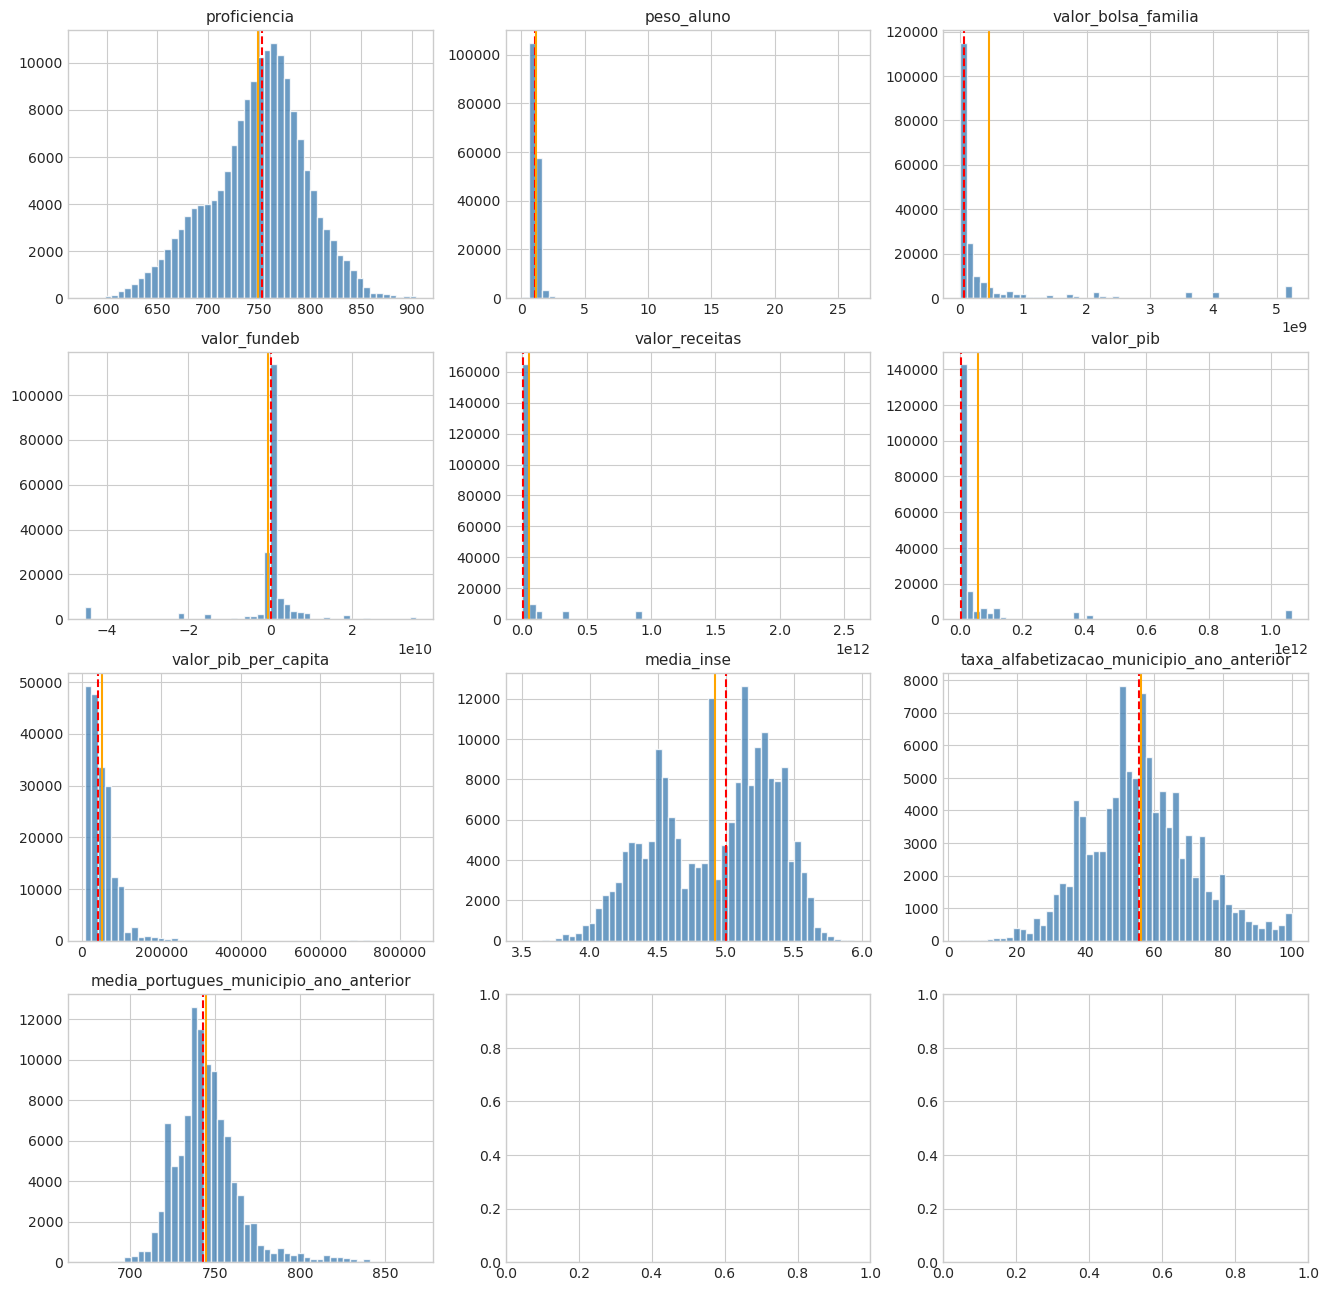

In [9]:
# ============================================================
# Análise de Distribuição das Principais Features
# Numéricas e Categóricas
# ============================================================

import polars as pl
import matplotlib.pyplot as plt
import numpy as np

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# ------------------------------------------------------------
# 1. Separar features numéricas e categóricas
# ------------------------------------------------------------
schema = df.collect_schema() if hasattr(df, "collect_schema") else df.schema

# Ajuste conforme o nome real do seu LazyFrame/DataFrame
# Se estiver usando o consolidado:
# df_analise = pl.scan_parquet("consolidado_base_alunos_municipios_por_uf/sigla_uf=*/*.parquet", hive_partitioning=True)
# ou se já tiver o DataFrame em memória:
df_analise = df  # troque pelo nome real se necessário

# Amostra determinística para estatísticas exploratórias e gráficos.
# As contagens oficiais das células seguintes continuam usando 100% da base lazy.
FRACAO_EDA_DISTRIBUICOES = FRACOES_AMOSTRAGEM["eda_correlacao"]
if isinstance(df_analise, pl.LazyFrame):
    limite_hash = max(1, round(FRACAO_EDA_DISTRIBUICOES * 10_000))
    df_sample = (
        df_analise
        .filter((pl.col("id_aluno").hash(seed=SEED_GLOBAL) % 10_000) < limite_hash)
        .collect(engine="streaming")
    )
else:
    df_sample = df_analise.sample(fraction=FRACAO_EDA_DISTRIBUICOES, seed=SEED_GLOBAL, shuffle=True)
print(f"Amostra EDA: {df_sample.height:,} registros ({FRACAO_EDA_DISTRIBUICOES:.1%}).")

colunas_numericas = [
    col for col, dtype in df_sample.schema.items()
    if dtype in (pl.Float32, pl.Float64, pl.Int8, pl.Int16, pl.Int32, pl.Int64, pl.UInt8, pl.UInt16, pl.UInt32, pl.UInt64)
    and col not in ["alfabetizado"]  # target já analisado
]

colunas_categoricas = [
    col for col, dtype in df_sample.schema.items()
    if dtype in (pl.Utf8, pl.Categorical, pl.Boolean, pl.Int8, pl.Int16, pl.Int32, pl.Int64)
    and col not in colunas_numericas
    and col not in ["id_aluno", "id_escola", "id_municipio", "processed_at"]  # IDs e timestamps
]

print("=== Features Numéricas identificadas ===")
print(colunas_numericas)
print(f"\nTotal: {len(colunas_numericas)}")

print("\n=== Features Categóricas identificadas ===")
print(colunas_categoricas)
print(f"\nTotal: {len(colunas_categoricas)}")

# ------------------------------------------------------------
# 2. Análise descritiva das features NUMÉRICAS
# ------------------------------------------------------------
print("\n" + "="*70)
print("DISTRIBUIÇÃO DAS FEATURES NUMÉRICAS")
print("="*70)

desc_numericas = (
    df_sample
    .select(colunas_numericas)
    .describe()
)

print(desc_numericas)

# Estatísticas extras: assimetria (skewness) e curtose
print("\n--- Assimetria (Skewness) e Curtose ---")
stats_extras = []
for col in colunas_numericas:
    serie = df_sample[col].drop_nulls()
    if serie.len() > 0:
        skew = serie.skew()
        # Curtose não tem método nativo direto em versões antigas do Polars,
        # calculada diretamente pelo Polars quando disponível
        try:
            kurt = serie.kurtosis()
        except:
            kurt = None
        stats_extras.append({
            "coluna": col,
            "skewness": round(skew, 3) if skew is not None else None,
            "kurtosis": round(kurt, 3) if kurt is not None else None,
            "nulos_pct": round(df_sample[col].null_count() / df_sample.height * 100, 2)
        })

df_stats_extras = pl.DataFrame(stats_extras).sort("skewness", descending=True)
print(df_stats_extras)

# Interpretação rápida da assimetria
print("\n--- Interpretação da Assimetria ---")
print("""
Skewness ≈ 0          → distribuição aproximadamente simétrica
Skewness > 1          → assimetria positiva forte (cauda à direita)
Skewness < -1         → assimetria negativa forte (cauda à esquerda)
|Skewness| entre 0.5 e 1 → assimetria moderada
""")

# ------------------------------------------------------------
# 3. Visualizações das principais features numéricas
# ------------------------------------------------------------
# Seleciona as mais relevantes (ajuste a lista conforme sua prioridade)
features_plot = [
    c for c in [
        "proficiencia", "peso_aluno", "valor_bolsa_familia",
        "valor_fundeb", "valor_receitas", "valor_pib",
        "valor_pib_per_capita", "media_inse",
        "taxa_alfabetizacao_municipio_ano_anterior",
        "media_portugues_municipio_ano_anterior"
    ] if c in colunas_numericas
]

n_feats = len(features_plot)
n_cols = 3
n_rows = (n_feats + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten() if n_feats > 1 else [axes]

for i, col in enumerate(features_plot):
    data = df_sample[col].drop_nulls().to_numpy()
    axes[i].hist(data, bins=50, color="steelblue", edgecolor="white", alpha=0.8)
    axes[i].axvline(np.median(data), color="red", linestyle="--", label=f"Mediana: {np.median(data):.2f}")
    axes[i].axvline(np.mean(data), color="orange", linestyle="-", label=f"Média: {np.mean(data):.2f}")
    axes[i].set_title(col, fontsize=11)


# Análise dos resultados – Distribuição das Features


## 1. Features Numéricas – Principais achados

| Feature | Comportamento observado | Interpretação | Recomendação |
|---|---|---|---|
| **proficiencia** | Quase simétrica, centrada em aproximadamente 740–750 | Boa distribuição, próxima da normal | Manter como está |
| **peso_aluno** | Forte concentração perto de 0 + cauda longa | Assimetria positiva extrema | Considerar log ou winsorização |
| **valor_bolsa_familia** | Fortemente assimétrica, com muitos valores baixos | Cauda longa à direita | `log1p` recomendado |
| **valor_fundeb** | Concentração em torno de 0 + outliers negativos e positivos | Possui valores negativos (estranho para um valor financeiro) | Investigar + possível log ou tratamento dos negativos |
| **valor_receitas** | Extremamente assimétrica | Poucos municípios com valores muito altos | `log1p` |
| **valor_pib** | Extremamente assimétrica | Mesmo padrão de receitas | `log1p` |
| **valor_pib_per_capita** | Assimetria positiva forte | Concentração em valores baixos | `log1p` |
| **media_inse** | Aproximadamente simétrica (4,0–5,5) | Boa distribuição | Manter |
| **taxa_alfabetizacao_municipio_ano_anterior** | Levemente assimétrica, centrada em aproximadamente 50–60% | Distribuição razoável | Manter ou verificar missing |
| **media_portugues_municipio_ano_anterior** | Quase simétrica | Boa distribuição | Manter |



Resumo numérico:

- Features de desempenho (proficiencia, media_inse, médias municipais) → distribuições bem comportadas.
- Features financeiras (bolsa, fundeb, receitas, pib) → forte assimetria positiva → candidatas fortes a transformação log.
- peso_aluno também precisa de atenção (possível outlier ou escala estranha).


## 2. Features Categóricas identificadas

nome_municipio, sigla_uf, rede_descricao, caderno, 
dataset_split, alfabetizado, nome uf, nome do município

#### Observações:

- alfabetizado já foi analisado (quase balanceado).
- sigla_uf e rede_descricao são as mais importantes para análise de predominância.
- nome_municipio / nome uf / nome do município têm alta cardinalidade → não são boas como features diretas (melhor usar id_municipio ou agregar).
- dataset_split deve refletir treino/teste/validação.


## 3. Conclusões para o requisito


### Pontos principais documentáveis

1. **Concentração / Dispersão**
   - Features financeiras apresentam alta dispersão e forte concentração em valores baixos.
   - `proficiencia` e `media_inse` apresentam dispersão moderada e distribuições relativamente bem distribuídas.

2. **Assimetria**
   - Forte assimetria positiva nas variáveis monetárias e em `peso_aluno`.
   - Features educacionais, como `proficiencia`, `media_inse` e as médias de desempenho, apresentam distribuições aproximadamente simétricas.

3. **Categorias predominantes**
   - Ainda é necessário analisar a tabela de frequências das variáveis categóricas, como `sigla_uf`, `rede_descricao`, `serie` e `presenca`.
   - Essa análise permitirá identificar as categorias predominantes, verificar possíveis desequilíbrios e avaliar a necessidade de agrupamento ou tratamento de categorias pouco frequentes.


## Documentação da Análise Exploratória de Dados (EDA)

### 1. Distribuição das Principais Features

#### 1.1 Features Numéricas

**Features bem comportadas (aproximadamente simétricas):**
- `proficiencia` → centrada em ~740–750
- `media_inse` → entre 4,0 e 5,5
- `media_portugues_municipio_ano_anterior`
- `taxa_alfabetizacao_municipio_ano_anterior`

**Features com forte assimetria positiva (cauda longa à direita):**
- `valor_bolsa_familia`
- `valor_fundeb`
- `valor_receitas`
- `valor_pib`
- `valor_pib_per_capita`
- `peso_aluno`

**Observações importantes:**
- Variáveis financeiras apresentam alta concentração em valores baixos e poucos municípios com valores extremos.
- `valor_fundeb` possui valores negativos (necessita investigação).
- Features de desempenho educacional tendem a ser mais simétricas e estáveis.

**Recomendações de tratamento:**
- Aplicar transformação `log1p` nas variáveis financeiras e em `peso_aluno`.
- Avaliar winsorização ou remoção de outliers extremos.
- Manter as features educacionais na escala original.

#### 1.2 Features Categóricas

Principais variáveis categóricas identificadas:
- `sigla_uf`
- `rede_descricao`
- `serie`
- `presenca`
- `preenchimento_caderno`
- `dataset_split`
- `caderno`
- `nome_municipio` / `nome uf` / `nome do município` (alta cardinalidade → não recomendadas como features diretas)

**Pontos de atenção:**
- `sigla_uf` e `rede_descricao` são as mais relevantes para análise de predominância e possível estratificação.
- Variáveis de nome de município/UF têm alta cardinalidade e devem ser evitadas como features brutas.
- `dataset_split` deve ser usada apenas para controle de treino/teste, nunca como feature preditiva.

---

### 2. Conclusões e Impactos na Modelagem

#### 2.1 Qualidade dos Dados
- Target de excelente qualidade (balanceado e sem missing).
- Missing crítico concentrado em features municipais de 2024 (problema de join temporal).
- Features educacionais apresentam boas distribuições.
- Features financeiras exigem transformação por causa da assimetria.

#### 2.2 Impactos nas Métricas e Modelos
- Como o target está balanceado, **Accuracy**, **F1**, **AUC-ROC** e **Balanced Accuracy** são todas métricas válidas.
- Ainda assim, recomenda-se sempre reportar a **matriz de confusão** e métricas por classe.
- Devido à heterogeneidade por UF, a avaliação deve ser feita também de forma estratificada geograficamente.

#### 2.3 Recomendações Prioritárias

1. **Corrigir os joins** com fallback para o ano anterior (maior impacto na qualidade dos dados).
2. Criar flags de missing para os blocos INSE, Censo e indicadores municipais.
3. Aplicar transformação log nas variáveis financeiras.
4. Usar **GroupKFold por `sigla_uf`** ou estratificação geográfica na validação.
5. Evitar usar nomes de município/UF como features diretas.
6. Investigar valores negativos em `valor_fundeb`.

---

### 3. Status dos Requisitos da EDA

| Requisito                                                                 | Status      |
|---------------------------------------------------------------------------|-------------|
| Examinar distribuição das principais features numéricas e categóricas     | ✅ Concluído |
| Identificar concentração, dispersão, assimetria e categorias predominantes| ✅ Concluído |

---
